=== 1. 데이터 기본 정보 ===
<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   label     5574 non-null   str  
 1   text_raw  5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB
None
  label                                           text_raw
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
행 수: 5574 (readme 기준 5,574건)
라벨 분포:
 label
ham     4827
spam     747
Name: count, dtype: int64

=== 2. 결측치/중복 처리 ===
결측치 개수:
 label       0
text_raw    0
dtype: int64
중복 행 개수: 403
중복 제거 후 행 수: 5171

=== 3-4. 텍스트 전처리 ===
정제 후 빈 문자열 개수: 6

=== 5. 분할 및 TF-IDF 수치화 ===
TF-IDF 행렬 크기 (train): (4136, 3000)
TF-IDF 행렬 크기 (test): (1035, 3000)
train

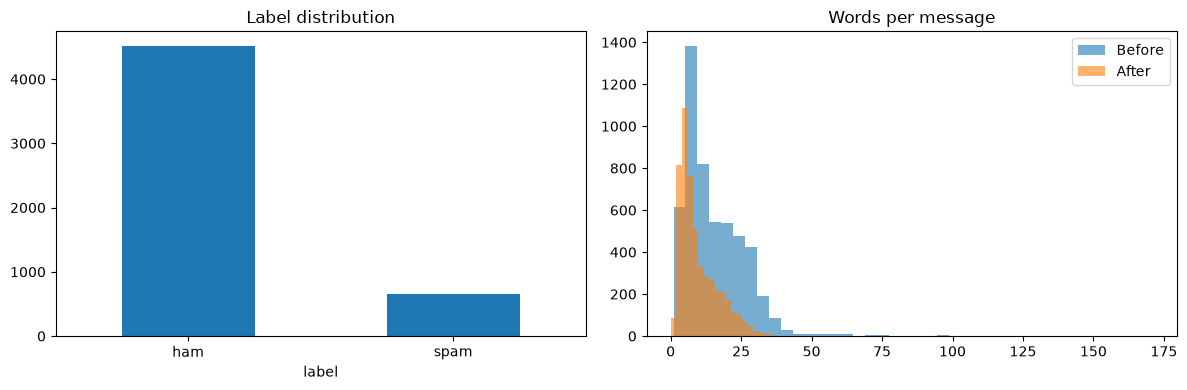

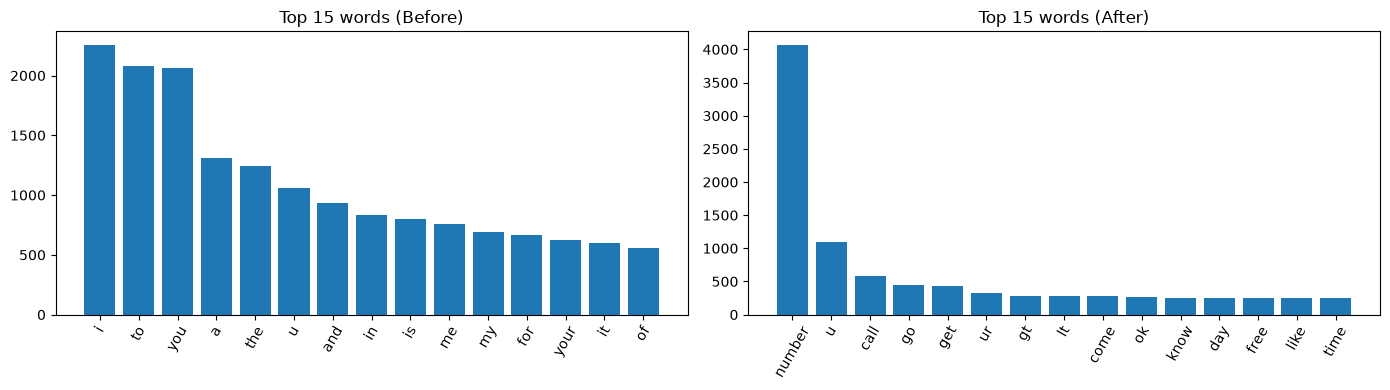


=== 7. 저장 완료 ===
저장 경로: ./data/cleaned/cleaned_text_data\SMSSpam_cleaned.csv


{'df':      label                                           text_raw  label_encoded  \
 0      ham  Go until jurong point, crazy.. Available only ...              0   
 1      ham                      Ok lar... Joking wif u oni...              0   
 2     spam  Free entry in 2 a wkly comp to win FA Cup fina...              1   
 3      ham  U dun say so early hor... U c already then say...              0   
 4      ham  Nah I don't think he goes to usf, he lives aro...              0   
 ...    ...                                                ...            ...   
 5166  spam  This is the 2nd time we have tried 2 contact u...              1   
 5167   ham               Will ü b going to esplanade fr home?              0   
 5168   ham  Pity, * was in mood for that. So...any other s...              0   
 5169   ham  The guy did some bitching but I acted like i'd...              0   
 5170   ham                         Rofl. Its true to its name              0   
 
                    

In [4]:
import csv
import os
import re
from collections import Counter

import matplotlib.pyplot as plt
import nltk
import pandas as pd
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split

# -------------------------------------------------------------------
# 설정값
# -------------------------------------------------------------------
FILE_PATH = './data/raw/text_dataset/SMSSpamCollection'
OUTPUT_DIR = './data/cleaned/cleaned_text_data'
OUTPUT_NAME = 'SMSSpam_cleaned.csv'
TEST_SIZE = 0.2
RANDOM_STATE = 42
MAX_FEATURES = 3000


# -------------------------------------------------------------------
# 0단계: 사전 준비
# -------------------------------------------------------------------
def download_resources():
    """NLTK 불용어 데이터 다운로드"""
    nltk.download('stopwords', quiet=True)


# -------------------------------------------------------------------
# 1단계: 데이터 로드 및 확인
# -------------------------------------------------------------------
def load_data(file_path):
    """TAB 구분 파일 로드. quoting=QUOTE_NONE: 문자열 안의 " 때문에 줄이 합쳐지는 것을 방지"""
    return pd.read_csv(
        file_path,
        sep='\t',
        names=['label', 'text_raw'],
        encoding='utf-8',
        quoting=csv.QUOTE_NONE,
    )


def inspect_data(df):
    """기본 정보 출력"""
    print('=== 1. 데이터 기본 정보 ===')
    print(df.info())
    print(df.head())
    print('행 수:', len(df), '(readme 기준 5,574건)')
    print('라벨 분포:\n', df['label'].value_counts())


# -------------------------------------------------------------------
# 2단계: 결측치/중복 확인 및 처리, 라벨 인코딩
# -------------------------------------------------------------------
def clean_data(df):
    """결측치 확인, 중복 제거, 라벨 인코딩(ham=0, spam=1)"""
    print('\n=== 2. 결측치/중복 처리 ===')
    print('결측치 개수:\n', df.isnull().sum())

    print('중복 행 개수:', df.duplicated().sum())
    df = df.drop_duplicates().reset_index(drop=True)
    print('중복 제거 후 행 수:', len(df))

    df['label_encoded'] = df['label'].map({'ham': 0, 'spam': 1})
    return df


# -------------------------------------------------------------------
# 3 & 4단계: 텍스트 정제, 불용어 제거, 어근 추출
# -------------------------------------------------------------------
def preprocess_text(text, stemmer, stop_words):
    """한 문장 정제: 소문자 -> 숫자 치환 -> 알파벳 외 제거 -> 토큰화 -> 불용어 제거 -> 스테밍"""
    text = text.lower()                             # 소문자 변환 (정규식보다 먼저!)
    text = re.sub(r'\d+', ' number ', text)         # 숫자 -> 토큰 치환 (스팸 판별 단서 보존)
    text = re.sub(r'[^a-z]', ' ', text)             # 알파벳 외 문자(특수문자/구두점) 제거
    words = text.split()                            # 공백 기준 단어 토큰화
    cleaned_words = [
        stemmer.stem(w) for w in words if w not in stop_words  # 불용어 제거 및 어근 추출
    ]
    return ' '.join(cleaned_words)                  # 문자열로 재결합


def apply_preprocessing(df):
    """전체 데이터에 텍스트 전처리 적용"""
    print('\n=== 3-4. 텍스트 전처리 ===')
    stemmer = PorterStemmer()
    stop_words = set(stopwords.words('english'))

    df['text_clean'] = df['text_raw'].apply(
        lambda t: preprocess_text(t, stemmer, stop_words)
    )
    print('정제 후 빈 문자열 개수:', (df['text_clean'] == '').sum())
    return df


# -------------------------------------------------------------------
# 5단계: 학습/테스트 분할 후 TF-IDF 수치화 (누수 방지)
# -------------------------------------------------------------------
def split_and_vectorize(df):
    """stratify 분할 후, 학습 데이터로만 TF-IDF fit"""
    print('\n=== 5. 분할 및 TF-IDF 수치화 ===')
    X_train_text, X_test_text, y_train, y_test = train_test_split(
        df['text_clean'],
        df['label_encoded'],
        test_size=TEST_SIZE,
        stratify=df['label_encoded'],
        random_state=RANDOM_STATE,
    )

    tfidf = TfidfVectorizer(max_features=MAX_FEATURES)
    X_train = tfidf.fit_transform(X_train_text)     # 학습 데이터로만 fit
    X_test = tfidf.transform(X_test_text)           # 테스트 데이터는 transform만

    print('TF-IDF 행렬 크기 (train):', X_train.shape)
    print('TF-IDF 행렬 크기 (test):', X_test.shape)
    print('train spam 비율:', round(y_train.mean(), 3))
    print('test spam 비율:', round(y_test.mean(), 3))
    return X_train, X_test, y_train, y_test, tfidf


# -------------------------------------------------------------------
# 6단계: 전처리 전/후 비교 (수치 + 시각화)
# -------------------------------------------------------------------
def compare_before_after(df, n_before):
    """전/후 수치 비교 및 그래프 출력"""
    print('\n=== 6. 전처리 전/후 데이터 비교 ===')
    print(df[['label', 'label_encoded', 'text_raw', 'text_clean']].head(3))

    # "전" 토큰도 구두점/특수문자를 분리해서 공정하게 비교
    raw_tokens = [
        w for t in df['text_raw'] for w in re.findall(r"[a-z0-9']+", t.lower())
    ]
    clean_tokens = [w for t in df['text_clean'] for w in t.split()]

    print('\n[행 수] 전:', n_before, '/ 후:', len(df))
    print('[전체 단어 수] 전:', len(raw_tokens), '/ 후:', len(clean_tokens))
    print('[고유 단어 수] 전:', len(set(raw_tokens)), '/ 후:', len(set(clean_tokens)))

    raw_len = df['text_raw'].str.split().str.len()
    clean_len = df['text_clean'].str.split().str.len()
    print('[평균 단어 수/메시지] 전: %.2f / 후: %.2f' % (raw_len.mean(), clean_len.mean()))

    # (1) 라벨 분포 / 메시지 길이 분포
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    df['label'].value_counts().plot(kind='bar', ax=axes[0], rot=0)
    axes[0].set_title('Label distribution')
    axes[1].hist(raw_len, bins=40, alpha=0.6, label='Before')
    axes[1].hist(clean_len, bins=40, alpha=0.6, label='After')
    axes[1].set_title('Words per message')
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    # (2) 상위 빈도 단어 Top 15 (전 vs 후)
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, tokens, title in zip(axes, [raw_tokens, clean_tokens], ['Before', 'After']):
        top = Counter(tokens).most_common(15)
        ax.bar([w for w, _ in top], [c for _, c in top])
        ax.set_title(f'Top 15 words ({title})')
        ax.tick_params(axis='x', rotation=60)
    plt.tight_layout()
    plt.show()


# -------------------------------------------------------------------
# 7단계: 정제 결과 저장
# -------------------------------------------------------------------
def save_cleaned(df, output_dir, file_name):
    """정제 결과 CSV 저장 (폴더가 없으면 자동 생성)"""
    os.makedirs(output_dir, exist_ok=True)
    df_cleaned = df[['label', 'text_clean', 'label_encoded']]
    path = os.path.join(output_dir, file_name)
    df_cleaned.to_csv(path, index=False, encoding='utf-8-sig')
    print('\n=== 7. 저장 완료 ===')
    print('저장 경로:', path)
    return path


# -------------------------------------------------------------------
# 전체 파이프라인
# -------------------------------------------------------------------
def SMSspam_piperun():
    """1~7단계를 순서대로 한 번에 실행"""
    download_resources()

    df = load_data(FILE_PATH)
    n_before = len(df)
    inspect_data(df)

    df = clean_data(df)
    df = apply_preprocessing(df)

    X_train, X_test, y_train, y_test, tfidf = split_and_vectorize(df)

    compare_before_after(df, n_before)
    save_cleaned(df, OUTPUT_DIR, OUTPUT_NAME)

    return {
        'df': df,
        'X_train': X_train,
        'X_test': X_test,
        'y_train': y_train,
        'y_test': y_test,
        'tfidf': tfidf,
    }


SMSspam_piperun()